# Retraining on the clean data: Consistency

**Goal.** Ask the earlier questions again, on the features recomputed through the factor package's cleaning code (see
[ARCHITECTURE.md](../../ARCHITECTURE.md)): which preprocessing and model, how good, and does it meet the criteria. The rules were fixed
before any of this ran in [RETRAIN_PROTOCOL.md](../../RETRAIN_PROTOCOL.md); the decision rules and success criteria are the earlier protocol's own.

**Disclosure.** Each group was a test group once in the earlier experiments, scored on the old features with the same 20 labels. This
notebook scores them again on changed features. Every choice here is made on validation groups only, and the new test result is
reported **beside** the earlier one. It shows the effect of cleaning on the same 20 students, not fresh independent evidence.

**Data.** 144 real student-sprints (20 rated) plus 175 simulated student-sprints, **training only**: never validated, never tested, labels are
estimates from the label model.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"
sys.path.insert(0, str(Path("../../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import retrain as R
from core import GROUPS, group_bootstrap, load, make_splits, md_table, metrics, paired_diff_bootstrap
from retrain_configs import CONFIGS

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

cfg = CONFIGS["consistency"]()
F = cfg.factor()
RES = F.results
d = load(F)
real, sim = d[d.source == "real"], d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
LABEL, ACT = cfg.label, cfg.activity
print(cfg.title, "| real", len(real), "| rated", len(gold), "| simulated (training only)", len(sim))

Consistency | real 144 | rated 20 | simulated (training only) 175


## 1. What cleaning changed in the data

In [2]:
old = pd.read_csv(Path("../dataset") / cfg.dataset_file, low_memory=False)
old = old[old.source == "real"].set_index("record_id")
cols = [c for c, _ in cfg.proposal]
rows = []
for c in cols:
    new_v = real.set_index("record_id")[c].astype(float)
    old_v = old[c].astype(float).reindex(new_v.index)
    ok = new_v.notna() & old_v.notna()
    rows.append({"feature": c, "median before": old_v.median(), "median now": new_v.median(),
                 "total now / before": new_v[ok].sum() / old_v[ok].sum() if old_v[ok].sum() else np.nan,
                 "rank agreement": new_v[ok].corr(old_v[ok], method="spearman")})
print("Real student-sprints: the proposal's features before and after cleaning")
display(pd.DataFrame(rows).set_index("feature").round(3))
rows = []
for c in cols:
    for name, frame in (("real", real), ("simulated", sim)):
        x = frame[c].astype(float).dropna()
        rows.append({"feature": c, "group": name, "p10": x.quantile(.1), "median": x.median(), "p90": x.quantile(.9), "missing": frame[c].isna().mean()})
print("Simulated students against real students (clean features)")
pd.DataFrame(rows).set_index(["feature", "group"]).round(3)

Real student-sprints: the proposal's features before and after cleaning


,median before,median now,total now / before,rank agreement
feature,,,,
C_AWR,0.143,0.143,0.944,0.977
C_DC,0.168,0.206,1.030,0.956
C_LI_norm,0.643,0.643,1.021,0.961
C_CV_norm,0.784,0.800,1.019,0.990


Simulated students against real students (clean features)


p10  median    p90  missing
feature   group                                   
C_AWR     real       0.000   0.143  0.357      0.0
          simulated  0.000   0.214  0.500      0.0
C_DC      real       0.000   0.206  1.000      0.0
          simulated  0.000   0.120  1.000      0.0
C_LI_norm real       0.286   0.643  1.000      0.0
          simulated  0.214   0.571  1.000      0.0
C_CV_norm real       0.465   0.800  1.000      0.0
          simulated  0.375   0.613  1.000      0.0

## 2. Splits and baselines (validation)

In [3]:
splits = make_splits(d)
splits.to_csv(F.splits, index=False)
role = splits.join(d[["source", "label_source"]], on="record_id")
chk = role.groupby(["outer_test", "inner_val", "role"]).size().unstack(fill_value=0)
assert not ((role.role == "val") & (role.source == "synthetic")).any() and not ((role.role == "test") & (role.source == "synthetic")).any()
print("20 combinations; simulated rows are never in validation or test. Records per role (first rows):")
display(chk.head(8))
base = pd.read_csv(RES / "baseline_predictions.csv")
rows = []
for name, g in base.groupby("name"):
    m = metrics(g.y, g.pred)
    rows.append({"baseline": name, "MAE": m["MAE"], "pearson": m["pearson"], "spearman": m["spearman"], "bias": m["bias"]})
display(pd.DataFrame(rows).set_index("baseline").sort_values("MAE").round(3))

20 combinations; simulated rows are never in validation or test. Records per role (first rows):


role                  test  train  val
outer_test inner_val                  
A          B            71    220   28
           C            71    227   21
           D            71    232   16
           E            71    240    8
B          A            28    220   71
           C            28    270   21
           D            28    275   16
           E            28    283    8

,MAE,pearson,spearman,bias
baseline,,,,
ridge (4 proposal features),0.072,0.887,0.791,0.019
"active days (AWR, linear)",0.098,0.861,0.781,0.015
"commits (log, linear)",0.099,0.770,0.768,0.005
1 - deadline share (linear),0.168,0.464,0.589,0.027
mean,0.195,-0.320,-0.309,-0.003
median,0.209,-0.271,-0.317,-0.067


## 3. Preprocessing: variants and label sources (Ridge, validation, selection without bias)

In [4]:
tuned = pd.read_csv(RES / "tuning_predictions.csv")
settings = json.load(open(RES / "settings.json"))
tuned.attrs["settings_path"] = str(RES / "settings.json")
rows = []
for (variant, lab, weight), g in tuned[tuned.model == "Ridge"].groupby(["variant", "lab", "weight"]):
    p, _ = R.bias_free(g)
    m = metrics(p.y, p.pred)
    rows.append({"variant": variant, "label source": lab, "weight": weight, "MAE": m["MAE"], "pearson": m["pearson"]})
prep = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
prep.round(3)

,variant,label source,weight,MAE,pearson
0,proposal 4,rated + propagated (real),1.0,0.075,0.883
1,proposal 4,rated + propagated (real),0.3,0.078,0.875
2,proposal 4,rated + propagated (real + synthetic),1.0,0.079,0.874
3,proposal 4,rated + propagated (real + synthetic),0.3,0.079,0.874
4,proposal 4,rated only,1.0,0.087,0.849


## 4. Ridge, Random Forest and Gradient Boosting, tuned, compared without selection bias

In [5]:
choice, table, pools, picks = R.decide(cfg, tuned, base, d, RES)
table.round(3)

,model,variant,MAE,bias,pearson,spearman
0,"Ridge (rated only, LOO alpha)",proposal,0.072,0.019,0.887,0.791
1,Random Forest,proposal 4,0.075,0.024,0.878,0.787
2,Gradient Boosting,proposal 4,0.075,0.023,0.877,0.769
3,Ridge,proposal 4,0.089,0.029,0.849,0.771


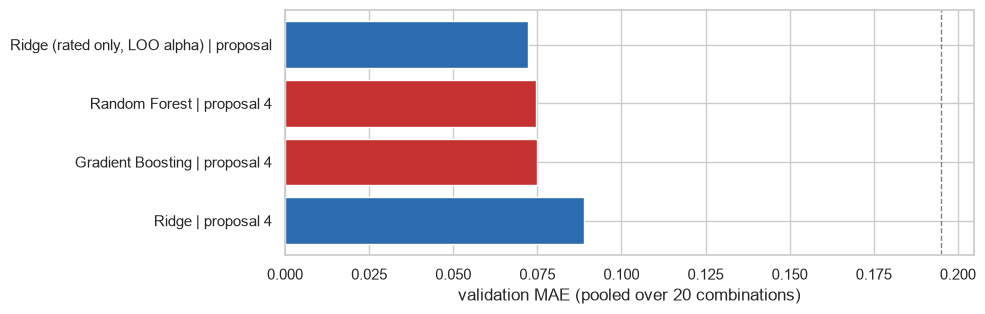

In [6]:
fig, ax = plt.subplots(figsize=(10, 0.45 * len(table) + 1.5))
labels = table.model + " | " + table.variant
ax.barh(labels[::-1], table.MAE[::-1], color=["#c53030" if "Forest" in l or "Boosting" in l else "#2b6cb0" for l in labels[::-1]])
for name, g in base.groupby("name"):
    if name in ("mean",):
        ax.axvline(metrics(g.y, g.pred)["MAE"], color="grey", ls="--", lw=1)
ax.set_xlabel("validation MAE (pooled over 20 combinations)")
fig.tight_layout(); plt.show()

## 5. The rule for keeping a complex model

In [7]:
rule = choice["rule"]
print(f"best Ridge-type model : {rule['ridge']}  (MAE {choice['ridge_best']['MAE']:.3f})")
print(f"best tree model       : {rule['complex']}  (MAE {choice['complex_best']['MAE']:.3f})")
print(f"gain {rule['gain_mae']:+.3f} MAE, 95% interval {rule['ci'][0]:+.3f} to {rule['ci'][1]:+.3f}, better in {rule['folds_better']} of 5 folds")
chosen_name = choice["complex_best"]["model"] if rule["passes_1_3"] else choice["ridge_best"]["model"]
chosen_variant = choice["complex_best"]["variant"] if rule["passes_1_3"] else choice["ridge_best"]["variant"]

print("\nmodel for the final test:", chosen_name, "|", chosen_variant)
json.dump({**choice, "chosen": [chosen_name, chosen_variant]}, open(RES / "model_choice.json", "w"), indent=1, default=float)

best Ridge-type model : Ridge (rated only, LOO alpha) | proposal  (MAE 0.072)
best tree model       : Random Forest | proposal 4  (MAE 0.075)
gain -0.002 MAE, 95% interval -0.009 to +0.002, better in 2 of 5 folds

model for the final test: Ridge (rated only, LOO alpha) | proposal


## 6. Final test, scored once

In [8]:
final, fits = R.final_test(cfg, d, chosen_name, chosen_variant, tuned, settings)
final.to_csv(RES / "final_test_predictions_unguarded.csv", index=False)
MAIN = f"{chosen_name} | {chosen_variant}"

fold_info = pd.DataFrame({o: fits[(chosen_name, chosen_variant, o)][2] for o in GROUPS}).T
display(fold_info)
print(len(final[final.name == MAIN]), "test predictions from", len(GROUPS), "models, each made by a model that never saw that student")

,alpha,label_config
A,10.0,rated only
B,3.162278,rated only
C,10.0,rated only
D,3.162278,rated only
E,3.162278,rated only


20 test predictions from 5 models, each made by a model that never saw that student


In [9]:
crit, m = R.criteria_table(cfg, final, MAIN, d)
crit.to_csv(RES / "final_test_criteria.csv", index=False)
display(crit.round(3))

,criterion,value,minimum,target,verdict,note
0,MAE / mean-guess MAE,0.36026,<= 0.5,<= 0.35,minimum met,"MAE 0.069, 95% interval 0.039-0.091"
1,Pearson and Spearman,0.893 / 0.803,>= 0.8 both,>= 0.9 / 0.85,minimum met,
2,"Beats active days (AWR, linear)",gain +0.023 (+25%),interval of the gain excludes 0,>= 10% lower,NOT MET,95% interval -0.003 to +0.062
3,Bias,0.00777,within +-0.05,within +-0.03,target met,
4,Calibration slope,1.037249,0.7-1.3,0.8-1.2,target met,
5,Rubric bands within one,1.0,>= 85%,">= 90%, exact >= 50%",target met,exact 90%
6,"MAE, students with activity",0.084086,<= 0.12,<= 0.1,target met,n = 15


,MAE,pearson,spearman,bias
model,,,,
"Ridge (rated only, LOO alpha) | proposal",0.069,0.893,0.803,0.008
"active days (AWR, linear)",0.092,0.863,0.772,0.007
"commits (log, linear)",0.098,0.769,0.774,0.006
1 - deadline share (linear),0.143,0.516,0.583,0.012
mean,0.192,-0.577,-0.582,-0.002
median,0.200,-0.562,-0.620,-0.053


outer_test,A,B,C,D,E
n,7.000,4.00,4.000,3.000,2.0
MAE,0.098,0.07,0.042,0.083,0.0


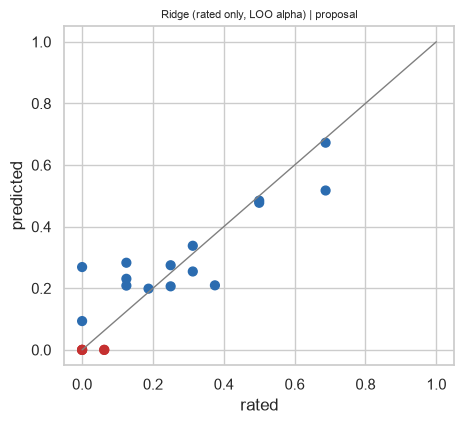

In [10]:
rows = []
for name, g in final.groupby("name"):
    mm = metrics(g.y, g.pred)
    rows.append({"model": name, "MAE": mm["MAE"], "pearson": mm["pearson"], "spearman": mm["spearman"], "bias": mm["bias"]})
display(pd.DataFrame(rows).set_index("model").sort_values("MAE").round(3))
pf = final[final.name == MAIN].assign(err=lambda x: (x.pred - x.y).abs())
display(pf.groupby("outer_test").agg(n=("err", "size"), MAE=("err", "mean")).round(3).T)
f = final[final.name == MAIN]
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(f.y, f.pred, c=np.where(f.activity > 0, "#2b6cb0", "#c53030"), s=40)
ax.plot([0, 1], [0, 1], color="grey", lw=1)
ax.set_xlabel("rated"); ax.set_ylabel("predicted"); ax.set_title(MAIN, fontsize=8)
fig.tight_layout(); plt.show()

## 7. Beside the earlier result (old features, same 20 students)

In [11]:
oldp = pd.read_csv(Path("../training/results/final_test_predictions.csv"))
mo, mn = metrics(oldp.y, oldp.pred), metrics(f.y, f.pred)
cmp = pd.DataFrame({"earlier (old features)": mo, "now (clean features)": mn}).loc[["n", "MAE", "RMSE", "bias", "pearson", "spearman", "calib_slope", "band_within_1", "band_exact"]]
display(cmp.round(3))
oldc = pd.read_csv(Path("../training/results/final_test_criteria.csv"))
print("Earlier criteria table (old features):")
display(oldc)

,earlier (old features),now (clean features)
n,20.000,20.000
MAE,0.059,0.069
RMSE,0.087,0.099
bias,0.013,0.008
pearson,0.923,0.893
spearman,0.874,0.803
calib_slope,1.086,1.037
band_within_1,1.000,1.000
band_exact,0.850,0.900


Earlier criteria table (old features):


,criterion,result,minimum (works),target,meets minimum,meets target
0,MAE / MAE of always predicting the mean,0.31 (0.059 / 0.192),<= 0.5,<= 0.35,True,True
1,Pearson,0.923,>= 0.8,>= 0.9,True,True
2,Spearman,0.874,>= 0.8,>= 0.85,True,True
3,Beats active days alone (`AWR`),gain +0.026 (95% CI -0.011 to 0.059),interval excludes 0,and >= 10% lower MAE,False,False
4,Bias,+0.013,within +-0.05,within +-0.03,True,True
5,Calibration slope,1.09,0.7 - 1.3,0.8 - 1.2,True,True
6,Rubric bands within one,100%,>= 85%,>= 90%,True,True
7,Rubric bands exact,85%,-,>= 50%,True,True
8,"MAE, students with activity",0.070,<= 0.12,<= 0.1,True,True


## 8. Reading the results

_Reading of the results: written after the run._